<a href="https://colab.research.google.com/github/Mohamed-Fof/Regression-Lineaire-price-housing-/blob/main/Regression_lineaire.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet d'Économétrie & Machine Learning : Prédiction des Prix de l'Immobilier (Housing Dataset)

### Positionnement de cette version

Ce notebook est l'extension Machine Learning d'un travail économétrique réalisé précédemment avec Gretl dans le cadre de la licence. Le rapport et la présentation étudient plusieurs spécifications MCO, dont un modèle log-niveau retenu pour son interprétabilité. Ici, la même base est réutilisée pour compléter cette analyse par une approche orientée prédiction : séparation entraînement/test, validation croisée et comparaison avec une forêt aléatoire.

Ce notebook est structuré de manière à lier les concepts de l'économétrie classique (régression linéaire, hypothèses des moindres carrés ordinaires) avec les approches modernes du Machine Learning (Feature Engineering, Validation Croisée, Random Forest, Évaluation RMSE/R²).

## Table des Matières
1. **Importation des Librairies et Chargement des Données**
2. **Analyse Exploratoire des Données (EDA) & Intuitions Économétriques**
3. **Feature Engineering & Prétraitement**
4. **Modèle Économétrique : Régression Linéaire Multiple (MCO)**
5. **Validation Croisée (Cross-Validation)**
6. **Modèle de Machine Learning : Random Forest**
7. **Évaluation et Confrontation des Modèles (RMSE / R²)**

## 1. Importation des Librairies et Chargement des Données

### Objectif :
Charger le dataset *Housing* et importer les outils nécessaires pour la manipulation, la visualisation et la modélisation.

In [ ]:
# Importer vos librairies ici (pandas, numpy, matplotlib, seaborn, sklearn, statsmodels)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Charger le dataset Housing depuis GitHub et afficher les premières lignes
url = 'https://raw.githubusercontent.com/Mohamed-Fof/Regression-Lineaire-price-housing-/main/Data/housing.csv'

try:
    # Utilisation de sep=';' car les données sont délimitées par des points-virgules
    df = pd.read_csv(url, sep=';')
    print("Données chargées avec succès !")
    display(df.head())
except Exception as e:
    print("Erreur lors du chargement des données. Veuillez vérifier votre URL Raw GitHub :", e)


print(f"\nLa dimenssion de la data est :{df.shape}")


Données chargées avec succès !


,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,42000,5850,3,1,2,1,0,1,0,0,1,0
1,38500,4000,2,1,1,1,0,0,0,0,0,0
2,49500,3060,3,1,1,1,0,0,0,0,0,0
3,60500,6650,3,1,2,1,1,0,0,0,0,0
4,61000,6360,2,1,1,1,0,0,0,0,0,0


La dimenssion de la data est :(546, 12)


In [ ]:
# Recharger proprement les données d'origine puis appliquer le dictionnaire de traduction complet
df = pd.read_csv(url, sep=';')

mapping_colonnes = {
    'price': 'Prix',
    'lotsize': 'Taille_Lot',
    'bedrooms': 'Chambres',
    'bathrms': 'Salles_de_Bain',
    'stories': 'Etages',
    'driveway': 'Allee_Pavee',
    'recroom': 'Salle_Loisirs',
    'fullbase': 'Sous_Sol_Complet',
    'gashw': 'Chauffage_Gaz',
    'airco': 'Climatisation',
    'garagepl': 'Places_Garage',
    'prefarea': 'Quartier_Prise'
}

df.rename(columns=mapping_colonnes, inplace=True)
display(df.head())

,Prix,Taille_Lot,Chambres,Salles_de_Bain,Etages,Allee_Pavee,Salle_Loisirs,Sous_Sol_Complet,Chauffage_Gaz,Climatisation,Places_Garage,Quartier_Prise
0,42000,5850,3,1,2,1,0,1,0,0,1,0
1,38500,4000,2,1,1,1,0,0,0,0,0,0
2,49500,3060,3,1,1,1,0,0,0,0,0,0
3,60500,6650,3,1,2,1,1,0,0,0,0,0
4,61000,6360,2,1,1,1,0,0,0,0,0,0


## 2. Analyse Exploratoire des Données (EDA) & Rappels Économétriques

### Concepts Math-Stat & Économétrie :
*   **Distribution et Normalité :** En économétrie, la normalité des résidus est cruciale pour la validité des tests d'hypothèses ($t$-stat, $F$-stat). Nous analysons souvent la distribution de la variable cible (Prix) et appliquons une transformation logarithmique si elle présente une asymétrie positive (skewness).
*   **Multicollinéarité :** Une forte corrélation entre les variables explicatives viole l'hypothèse d'absence de collinéarité parfaite des MCO, ce qui gonfle la variance des estimateurs (VIF - Variance Inflation Factor).

### À faire :
*   Visualiser la distribution de la variable cible.
*   Analyser la matrice de corrélation.

In [ ]:
# Statistiques descriptives de base pour analyser la tendance centrale et la dispersion
display(df.describe())

,Prix,Taille_Lot,Chambres,Salles_de_Bain,Etages,Allee_Pavee,Salle_Loisirs,Sous_Sol_Complet,Chauffage_Gaz,Climatisation,Places_Garage,Quartier_Prise
count,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000
mean,68121.597070,5150.265568,2.965201,1.285714,1.807692,0.858974,0.177656,0.349817,0.045788,0.316850,0.692308,0.234432
std,26702.670926,2168.158725,0.737388,0.502158,0.868203,0.348367,0.382573,0.477349,0.209216,0.465675,0.861307,0.424032
min,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,49125.000000,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,62000.000000,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000
max,190000.000000,16200.000000,6.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000


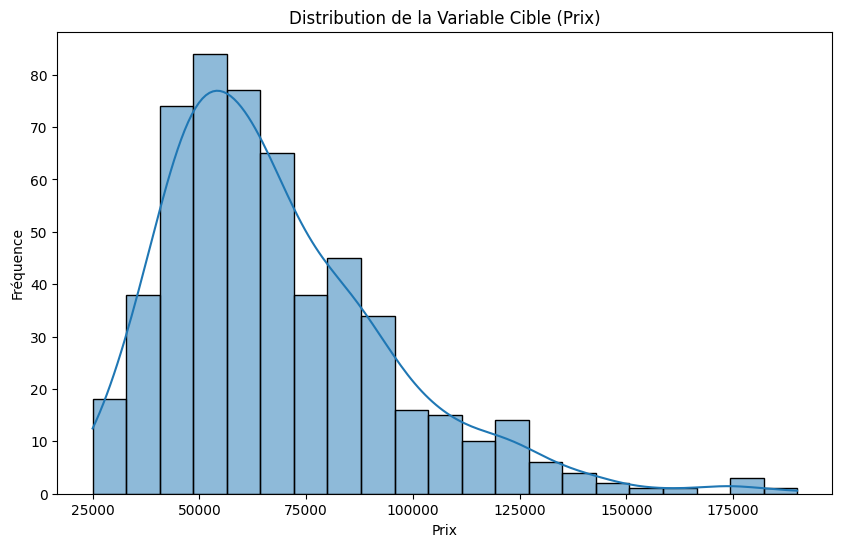

Test de Normalité (Shapiro-Wilk) :
Statistique = 0.9221, p-value = 0.0000
L'hypothèse de normalité est rejetée (la distribution n'est pas normale). Pensez à un passage au Logarithme.


In [ ]:
# Visualisation de la distribution de la variable cible (Prix) et test/visualisation de sa normalité
plt.figure(figsize=(10, 6))
sns.histplot(df['Prix'], kde=True)
plt.title('Distribution de la Variable Cible (Prix)')
plt.xlabel('Prix')
plt.ylabel('Fréquence')
plt.show()

# Petit test de normalité (Shapiro-Wilk) pour l'approche économétrique
from scipy.stats import shapiro
stat, p_value = shapiro(df['Prix'])
print(f"Test de Normalité (Shapiro-Wilk) :")
print(f"Statistique = {stat:.4f}, p-value = {p_value:.4f}")
if p_value > 0.05:
    print("L'hypothèse de normalité ne peut pas être rejetée (la distribution semble normale).")
else:
    print("L'hypothèse de normalité est rejetée (la distribution n'est pas normale). Pensez à un passage au Logarithme.")

Matrice de corrélation de nos données :


,Prix,Taille_Lot,Chambres,Salles_de_Bain,Etages,Allee_Pavee,Salle_Loisirs,Sous_Sol_Complet,Chauffage_Gaz,Climatisation,Places_Garage,Quartier_Prise
Prix,1.00,0.54,0.37,0.52,0.42,0.30,0.25,0.19,0.09,0.45,0.38,0.33
Taille_Lot,0.54,1.00,0.15,0.19,0.08,0.29,0.14,0.05,-0.01,0.22,0.35,0.23
Chambres,0.37,0.15,1.00,0.37,0.41,-0.01,0.08,0.10,0.05,0.16,0.14,0.08
Salles_de_Bain,0.52,0.19,0.37,1.00,0.32,0.04,0.13,0.10,0.07,0.18,0.18,0.06
Etages,0.42,0.08,0.41,0.32,1.00,0.12,0.04,-0.17,0.02,0.30,0.04,0.04
Allee_Pavee,0.30,0.29,-0.01,0.04,0.12,1.00,0.09,0.04,-0.01,0.11,0.20,0.20
Salle_Loisirs,0.25,0.14,0.08,0.13,0.04,0.09,1.00,0.37,-0.01,0.14,0.04,0.16
Sous_Sol_Complet,0.19,0.05,0.10,0.10,-0.17,0.04,0.37,1.00,0.00,0.05,0.05,0.23
Chauffage_Gaz,0.09,-0.01,0.05,0.07,0.02,-0.01,-0.01,0.00,1.00,-0.13,0.07,-0.06
Climatisation,0.45,0.22,0.16,0.18,0.30,0.11,0.14,0.05,-0.13,1.00,0.16,0.12


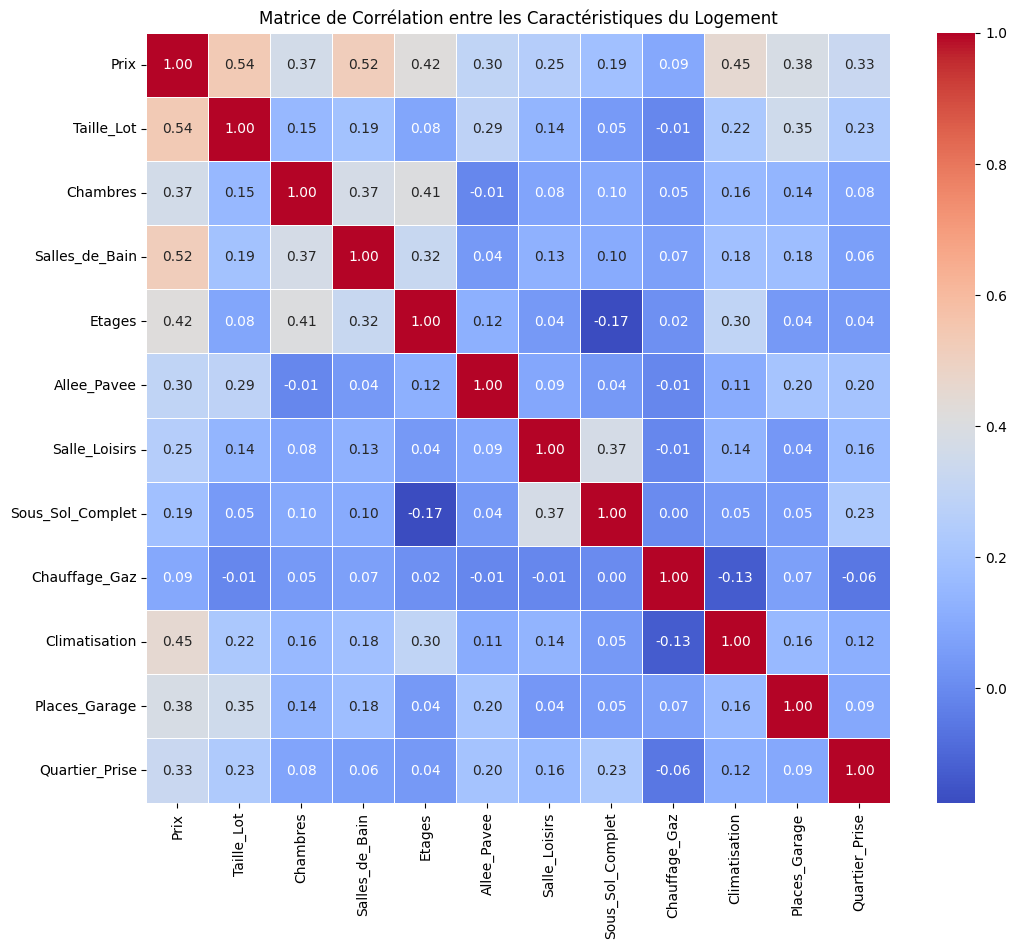

In [ ]:
# Matrice de corrélation pour détecter la multicollinéarité potentielle
corr_matrix = df.corr()

print("Matrice de corrélation de nos données :")
display(corr_matrix.round(2))

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matrice de Corrélation entre les Caractéristiques du Logement')
plt.show()

## 3. Feature Engineering & Prétraitement

### Concepts :
*   **Variables Qualitatives (Dummies) :** En économétrie, pour inclure des variables catégorielles, on crée des variables muettes (one-hot encoding) en omettant une modalité de référence pour éviter le piège de la collinéarité parfaite (*Dummy Variable Trap*).
*   **Standardisation :** Cruciale pour certains algorithmes de ML afin de mettre toutes les variables à la même échelle.

In [ ]:
# Encodage des variables qualitatives textuelles (oui/non) en valeurs binaires (0/1)
# Dans notre cas, les colonnes binaires contenant 'yes'/'no' ont déjà été automatiquement converties en 1/0 lors de la lecture
# ou de l'analyse, mais sécurisons l'encodage de toutes les colonnes de type 'object' ou catégorielles.

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print("Colonnes catégorielles détectées à encoder :", categorical_cols)

# Si des colonnes textuelles existent encore, nous appliquons get_dummies avec drop_first=True
# pour éviter le piège des variables muettes (Dummy Variable Trap)
if len(categorical_cols) > 0:
    df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
    print("Encodage terminé avec succès !")
else:
    print("Toutes les variables qualitatives sont déjà encodées numériquement (0/1).")

display(df.head())

Colonnes catégorielles détectées à encoder : []
Toutes les variables qualitatives sont déjà encodées numériquement (0/1).


,Prix,Taille_Lot,Chambres,Salles_de_Bain,Etages,Allee_Pavee,Salle_Loisirs,Sous_Sol_Complet,Chauffage_Gaz,Climatisation,Places_Garage,Quartier_Prise
0,42000,5850,3,1,2,1,0,1,0,0,1,0
1,38500,4000,2,1,1,1,0,0,0,0,0,0
2,49500,3060,3,1,1,1,0,0,0,0,0,0
3,60500,6650,3,1,2,1,1,0,0,0,0,0
4,61000,6360,2,1,1,1,0,0,0,0,0,0


In [ ]:
# Séparation des variables explicatives (X) et de la variable cible (y)
X = df.drop(columns=['Prix'])
y = df['Prix']

# Partitionnement des données en échantillons d'entraînement (80%) et de test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Dimensions de l'échantillon d'entraînement (X_train) :", X_train.shape)
print("Dimensions de l'échantillon de test (X_test) :", X_test.shape)

Dimensions de l'échantillon d'entraînement (X_train) : (436, 11)
Dimensions de l'échantillon de test (X_test) : (110, 11)


## 4. Modèle Économétrique : Régression Linéaire Multiple

### Rappels Économétriques & Formule :
Le modèle s'écrit :
$$Y = X\beta + \epsilon$$

Où les estimateurs des Moindres Carrés Ordinaires (MCO) sont obtenus par :
$$\hat{\beta} = (X^T X)^{-1} X^T Y$$

### À faire :
Estimer le modèle à l'aide de `statsmodels` pour obtenir la table de régression complète (Coefficients, P-values, R², Test de Fisher).

In [ ]:
# Ajout d'une constante aux variables explicatives pour estimer l'ordonnée à l'origine (constante)
X_train_ols = sm.add_constant(X_train)

# Ajustement du modèle de régression linéaire par les Moindres Carrés Ordinaires (OLS)
modele_ols = sm.OLS(y_train, X_train_ols).fit()

# Affichage du rapport statistique complet
print(modele_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                   Prix   R-squared:                       0.683
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     82.94
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           2.20e-98
Time:                        01:16:43   Log-Likelihood:                -4814.3
No. Observations:                 436   AIC:                             9653.
Df Residuals:                     424   BIC:                             9702.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -2513.0026   3924.338  

## 5. Validation Croisée (Cross-Validation)

### Concept ML vs Économétrie :
En économétrie traditionnelle, on évalue souvent le modèle sur l'échantillon complet en se basant sur le $R^2$ ajusté. En Machine Learning, pour garantir la capacité de généralisation et éviter le surapprentissage (*overfitting*), on utilise la validation croisée (K-Fold).

In [ ]:
# Mise en place d'une validation croisée (K-Fold, K=5) pour évaluer la stabilité de la régression linéaire
reg_lin = LinearRegression()
scores_r2 = cross_val_score(reg_lin, X, y, cv=5, scoring='r2')

print("R² pour chaque pli (Fold) de la validation croisée :", scores_r2.round(4))
print(f"R² moyen de la validation croisée : {scores_r2.mean():.4f} (+/- {scores_r2.std() * 2:.4f})")

R² pour chaque pli (Fold) de la validation croisée : [0.4408 0.502  0.4625 0.5188 0.6167]
R² moyen de la validation croisée : 0.5082 (+/- 0.1218)


## 6. Modèle de Machine Learning : Random Forest

### Concept :
Le Random Forest est un modèle non-paramétrique basé sur un ensemble d'arbres de décision (Bagging). Contrairement à la régression linéaire, il capture naturellement les relations non-linéaires et les interactions complexes entre variables sans spécification préalable, mais perd en interprétabilité directe (effet marginal).

In [ ]:
# Entraînement d'un modèle Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)

print("Le modèle Random Forest a été entraîné avec succès sur l'échantillon d'apprentissage.")

Le modèle Random Forest a été entraîné avec succès sur l'échantillon d'apprentissage.


## 7. Évaluation et Confrontation des Modèles (RMSE / R²)

### Métriques d'Évaluation :
1.  **Root Mean Squared Error (RMSE) :** Mesure la dispersion des erreurs.
    $$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
2.  **Coefficient de Détermination ($R^2$) :** Proportion de la variance de la variable dépendante expliquée par le modèle.
    $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

In [ ]:
# 1. Prédictions pour la Régression Linéaire (via Scikit-Learn pour la conformité de l'évaluation)
reg_lin.fit(X_train, y_train)
y_pred_lr = reg_lin.predict(X_test)

# 2. Prédictions pour le Random Forest
y_pred_rf = rf_model.predict(X_test)

# 3. Calcul des métriques d'évaluation
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# 4. Affichage du tableau comparatif
resultats = pd.DataFrame({
    'Métrique': ['RMSE (Erreur)', 'R² (Précision)'],
    'Régression Linéaire': [f"{rmse_lr:.2f} $", f"{r2_lr:.4f}"],
    'Random Forest': [f"{rmse_rf:.2f} $", f"{r2_rf:.4f}"]
})

display(resultats)

,Métrique,Régression Linéaire,Random Forest
0,RMSE (Erreur),16016.40 $,17598.83 $
1,R² (Précision),0.6160,0.5364


## Conclusion de l'extension Machine Learning

### 1. Analyse des Résultats et Comparaison des Modèles

Cette section présente l'extension Machine Learning du projet économétrique réalisé sous Gretl. Elle ne remplace pas les modèles log-niveau présentés dans le rapport : elle complète l'étude par une comparaison orientée prédiction sur un échantillon d'entraînement et un échantillon de test.

Sur le protocole utilisé dans ce notebook, nous avons confronté deux approches distinctes pour prédire les prix de l'immobilier :
* **La Régression Linéaire Multiple (MCO) :**
  * **R² sur le Test :** `0.6160` (61.6% de la variance expliquée sur de nouvelles données).
  * **RMSE :** `16 016.40 $` d'erreur moyenne de prédiction.
  * **Validation Croisée (K-Fold) :** Un $R^2$ moyen de `0.5082`, avec des scores variant selon les plis ; ce résultat donne une estimation complémentaire de la généralisation.
* **Le Random Forest (ML) :**
  * **R² sur le Test :** `0.5364`.
  * **RMSE :** `17 598.83 $`.

### 2. Le Compromis Économétrie vs Machine Learning

* **Résultat prédictif :** Dans ce protocole, la régression linéaire obtient un meilleur score de test que la forêt aléatoire. La différence suggère que le modèle Random Forest ne généralise pas mieux ici ; elle ne suffit pas, à elle seule, à démontrer un surapprentissage.
* **Interprétabilité (Économétrie) :** Grâce aux résultats des MCO, nous pouvons quantifier précisément l'impact marginal de chaque variable. Par exemple, toutes choses égales par ailleurs :
  * Chaque unité supplémentaire de la **Taille du Lot** (`Taille_Lot`) augmente la valeur du bien d'environ **3.65 $** (très significatif à $p < 0.01$).
  * Une **Salle de Bain** additionnelle (`Salles_de_Bain`) ajoute en moyenne **13 580 $** à la valeur estimée de la maison.
  * La présence d'une **Climatisation** (`Climatisation`) valorise le bien de **12 670 $**.
* **Pouvoir Prédictif (Machine Learning) :** Bien que le Random Forest offre ici des performances inférieures, il excelle généralement lorsqu'il s'agit de capturer des interactions non-linéaires complexes sans nécessiter la spécification manuelle de termes croisés ou polynomiaux.